# 02 — Détection d'anomalies : Random Forest

Cible : `label` (0 = normal, 1 = attaque) · Entrée : `data/processed/*` (notebook 01) · Classe minoritaire = **normal** (~23 %), les attaques sont ~77 % du trafic.

## Workflow
1. Chargement, pipeline `prétraitement → [rééchantillonnage] → Random Forest`
2. **Baseline** (hyper-paramètres par défaut, sans équilibrage)
3. **Équilibrage** en validation croisée (aucun / poids de classe / ROS / SMOTE / SMOTENC), choix par **règle de parcimonie**
4. **Réglage** (`RandomizedSearchCV`, 20 tirages, F1 macro)
5. Courbe d'apprentissage et **écart train / validation**
6. Évaluation en validation
7. **Seuil** (F1 macro) et **calibration des probabilités** — choisis sur la validation **uniquement**
8. **Test lu une seule fois** (seuil par défaut et seuil réglé)
9. Interprétation (Gini, permutation) et analyse des erreurs
10. Sauvegarde

> Métriques : F1 macro et PR-AUC (les deux classes comptent), spécificité (taux de normal bien reconnu), FPR/FNR. L'accuracy seule est trompeuse.
> Depuis le correctif de fuite (doublons train/test supprimés, `src_port` retiré), les scores sont plus bas qu'avant : c'est attendu, il n'y a plus de mémorisation.

In [1]:
import sys, time, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
import ml_utils as U
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.metrics import confusion_matrix, make_scorer, recall_score, brier_score_loss
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
U.set_style(); U.set_seeds()
RS = U.RANDOM_STATE
N_JOBS = 5
cfg = U.load_config(); NUM, CAT = cfg["numeric_cols"], cfg["categorical_cols"]; TYPE_ORDER = U.get_type_order(cfg)
X_train, y_tr = U.load_split("train"); X_valid, y_va = U.load_split("valid"); X_test, y_te = U.load_split("test")
ytr, yva, yte = y_tr["label"].to_numpy(), y_va["label"].to_numpy(), y_te["label"].to_numpy()
print({"train": X_train.shape, "valid": X_valid.shape, "test": X_test.shape})
print("Part d'attaques (train/valid/test) :", ytr.mean().round(4), yva.mean().round(4), yte.mean().round(4))

{'train': (65007, 35), 'valid': (21482, 35), 'test': (21438, 35)}
Part d'attaques (train/valid/test) : 0.7674 0.7714 0.773


## 1. Pipeline

`U.make_model_pipeline` regroupe prétraitement (`pre`), rééchantillonnage (`sampler`) et modèle (`model`). En validation croisée **tout est ré-appris sur chaque pli
d'apprentissage** et le rééchantillonnage ne touche jamais le pli de validation (pipeline `imblearn`). Un Random Forest n'a pas besoin de standardisation (`scale=False`).
La stratégie « poids de classe » règle `class_weight="balanced_subsample"` sur l'estimateur ; le pipeline est alors identique à « aucun ».

In [2]:
def make_pipe(strategy="none", n_jobs=N_JOBS, **rf_params):
    kw = dict(n_jobs=n_jobs, random_state=RS, class_weight="balanced_subsample" if strategy == "class_weight" else None)
    kw.update(rf_params)
    return U.make_model_pipeline(RandomForestClassifier(**kw), NUM, CAT, strategy=strategy, scale=False, random_state=RS)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
sub = X_train.sample(50000, random_state=RS).index          # sous-échantillon pour la CV et le réglage (le modèle final voit tout le train)
Xs, ys = X_train.loc[sub], y_tr.loc[sub, "label"].to_numpy()
make_pipe()

,steps,"[('pre', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_log', ...), ('num_lin', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_

## 2. Baseline
Random Forest par défaut (100 arbres, sans équilibrage) sur **tout le train**, évalué en validation (seuil 0,5).

In [3]:
t0 = time.time(); base = make_pipe("none", n_estimators=100).fit(X_train, ytr); t_base = time.time() - t0
p_base = base.predict_proba(X_valid)[:, 1]
base_valid = U.binary_metrics(yva, (p_base >= .5).astype(int), scores=p_base, proba=p_base)
print(f"Temps d'entraînement : {t_base:.1f}s")
display(pd.Series(base_valid).to_frame("baseline (validation)").T.round(4))

Temps d'entraînement : 4.2s


,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,mcc,tn,fp,fn,tp,fpr,fnr,roc_auc,pr_auc,brier
baseline (validation),0.9978,0.9966,0.9983,0.9989,0.9943,0.9986,0.9969,0.9978,0.9938,4882.0000,28.0000,19.0000,16553.0000,0.0057,0.0011,0.9999,0.9999,0.0016


## 3. Choix de la stratégie d'équilibrage

Validation croisée stratifiée à 3 plis sur un sous-échantillon de 50 000 lignes du train ; le rééchantillonnage est refait dans chaque pli.
Les cinq stratégies sont comparées sur F1 macro, PR-AUC, accuracy équilibrée, rappel (attaques) et **spécificité** (normal, la classe minoritaire).

**Règle de parcimonie** (`U.select_by_parsimony`) : on retient la stratégie **la plus simple** (aucun < poids de classe < ROS < SMOTE < SMOTENC) dont le F1 macro moyen est
dans l'écart-type de la meilleure. Choisir l'`argmax` reviendrait à choisir sur du bruit de validation croisée.

none              10s  F1 macro = 0.9966 ± 0.0001


class_weight       5s  F1 macro = 0.9967 ± 0.0000


ros                7s  F1 macro = 0.9968 ± 0.0003


smote              7s  F1 macro = 0.9969 ± 0.0003


smotenc           13s  F1 macro = 0.9968 ± 0.0001


,f1_macro,pr_auc,balanced_accuracy,recall,specificity
Aucun,0.9966 ± 0.0001,0.9999 ± 0.0001,0.9961 ± 0.0004,0.9988 ± 0.0003,0.9934 ± 0.0010
Poids de classe,0.9967 ± 0.0000,0.9999 ± 0.0001,0.9962 ± 0.0004,0.9989 ± 0.0004,0.9934 ± 0.0011
Sur-échantillonnage aléatoire,0.9968 ± 0.0003,0.9999 ± 0.0001,0.9966 ± 0.0006,0.9986 ± 0.0003,0.9946 ± 0.0014
SMOTE,0.9969 ± 0.0003,0.9999 ± 0.0001,0.9969 ± 0.0005,0.9986 ± 0.0004,0.9952 ± 0.0012
SMOTENC,0.9968 ± 0.0001,0.9999 ± 0.0001,0.9968 ± 0.0004,0.9986 ± 0.0002,0.9950 ± 0.0010



=> Meilleur F1 macro brut : smote ; stratégie retenue (parcimonie) : none


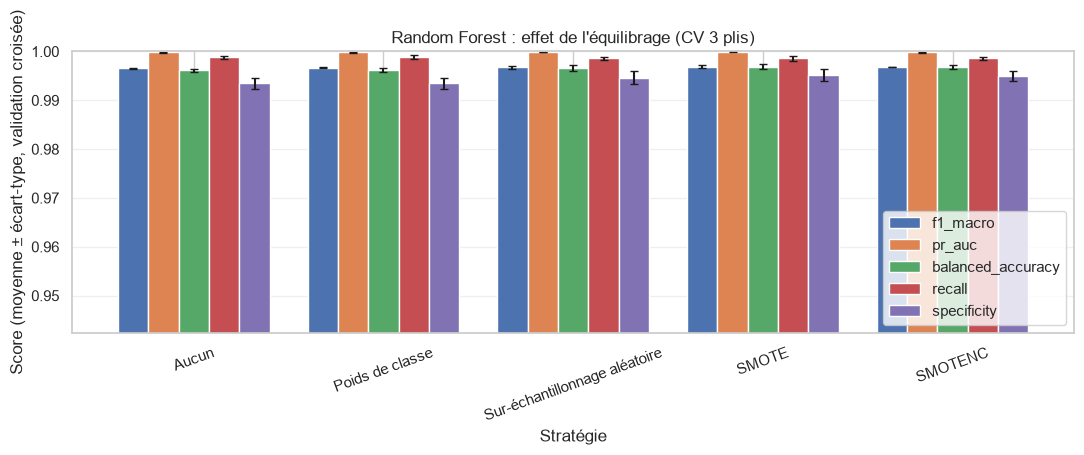

In [4]:
SCORING = {"f1_macro": "f1_macro", "pr_auc": "average_precision", "balanced_accuracy": "balanced_accuracy",
           "recall": "recall", "specificity": make_scorer(recall_score, pos_label=0)}
METRICS = list(SCORING)
rows = {}
for name in U.STRATEGIES:
    t0 = time.time()
    r = cross_validate(make_pipe(name, n_jobs=2, n_estimators=100), Xs, ys, cv=cv, n_jobs=3, scoring=SCORING)
    row = {}
    for m in METRICS:
        row[m] = r[f"test_{m}"].mean(); row[f"{m}_std"] = r[f"test_{m}"].std()
    row["temps_s"] = time.time() - t0
    rows[name] = row
    print(f"{name:13s} {time.time()-t0:6.0f}s  F1 macro = {row['f1_macro']:.4f} ± {row['f1_macro_std']:.4f}")
bal = pd.DataFrame(rows).T
disp = pd.DataFrame({m: bal[m].map("{:.4f}".format) + " ± " + bal[f"{m}_std"].map("{:.4f}".format) for m in METRICS})
display(disp.rename(index=U.STRATEGY_LABELS))
best_strategy = U.select_by_parsimony(bal, "f1_macro", "f1_macro_std", list(U.STRATEGIES))
argmax_strategy = bal["f1_macro"].idxmax()
print(f"\n=> Meilleur F1 macro brut : {argmax_strategy} ; stratégie retenue (parcimonie) : {best_strategy}")
fig, ax = plt.subplots(figsize=(11, 4.5))
U.plot_cv_comparison(bal.rename(index=U.STRATEGY_LABELS), METRICS, [f"{m}_std" for m in METRICS], "Random Forest : effet de l'équilibrage (CV 3 plis)", ax=ax)
plt.tight_layout(); U.savefig(fig, "02_balancing_cv"); plt.show()

## 4. Réglage des hyper-paramètres

`RandomizedSearchCV` (20 tirages × 3 plis) avec la stratégie retenue, critère **F1 macro**. `max_depth`, `min_samples_leaf`, `max_features` contrôlent la complexité (surapprentissage) ;
`n_estimators` réduit la variance. Le score d'entraînement est conservé pour examiner l'écart train / CV.

In [5]:
param_dist = {"model__n_estimators": [100, 200, 300], "model__max_depth": [None, 10, 15, 20, 30],
              "model__min_samples_split": [2, 5, 10, 20], "model__min_samples_leaf": [1, 2, 4, 8],
              "model__max_features": ["sqrt", "log2", 0.3, 0.5]}
t0 = time.time()
search = RandomizedSearchCV(make_pipe(best_strategy, n_jobs=2), param_dist, n_iter=20, cv=cv, scoring="f1_macro",
                            random_state=RS, n_jobs=3, refit=False, return_train_score=True)
search.fit(Xs, ys); t_search = time.time() - t0; print(f"Recherche terminée en {t_search:.0f}s")
res = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
cols = ["mean_test_score", "std_test_score", "mean_train_score", "mean_fit_time"] + [c for c in res.columns if c.startswith("param_")]
display(res[cols].head(8).round(4))
best_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
print("Meilleurs hyper-paramètres :", best_params)

Recherche terminée en 395s


,mean_test_score,std_test_score,mean_train_score,mean_fit_time,param_model__n_estimators,param_model__min_samples_split,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth
10,0.9967,0.0001,0.9999,4.2975,100,2,1,sqrt,20
9,0.9964,0.0002,0.9989,25.4829,300,2,2,0.3000,30
14,0.9963,0.0002,0.9986,6.9773,100,10,1,sqrt,20
18,0.9963,0.0001,0.9985,19.6407,300,5,2,sqrt,30
15,0.9961,0.0001,0.9984,54.6425,300,2,2,0.5000,15
4,0.9958,0.0003,0.9978,45.6348,300,20,1,0.5000,30
0,0.9958,0.0004,0.9975,8.5023,300,10,2,log2,30
3,0.9956,0.0003,0.9974,28.1382,300,5,4,0.3000,30


Meilleurs hyper-paramètres : {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


## 5. Courbe d'apprentissage et surapprentissage
Courbe F1 macro (train vs validation croisée) sur 30 000 lignes du sous-échantillon. Un écart durable = surapprentissage ; deux courbes qui se rejoignent = plus de données n'aideraient presque pas.

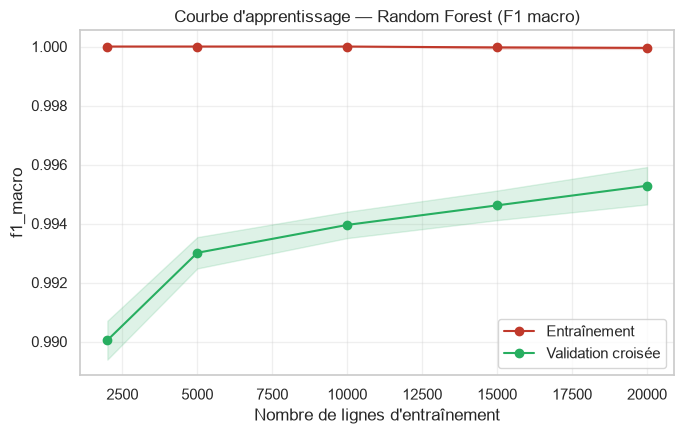

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
U.plot_learning_curve(make_pipe(best_strategy, n_jobs=2, **best_params), Xs.iloc[:30000], ys[:30000], cv=cv, scoring="f1_macro",
                      title="Courbe d'apprentissage — Random Forest (F1 macro)", ax=ax, train_sizes=[.1, .25, .5, .75, 1.0], n_jobs=3)
plt.tight_layout(); U.savefig(fig, "02_learning_curve"); plt.show()

## 6. Modèle final et évaluation en validation
Réapprentissage sur **tout le train** (stratégie et hyper-paramètres retenus). On compare train et validation : un Random Forest atteint presque toujours ~1,0 sur le train (arbres profonds),
l'écart est donc attendu ; ce qui compte est le niveau en validation.

Temps d'entraînement : 6.4s sur 65007 lignes


,accuracy,precision,recall,specificity,f1,f1_macro,roc_auc,pr_auc,mcc
train,0.9999,0.9998,1.0000,0.9994,0.9999,0.9998,1.0000,1.0000,0.9996
validation,0.9978,0.9982,0.9989,0.9939,0.9986,0.9968,1.0000,1.0000,0.9937
baseline (valid),0.9978,0.9983,0.9989,0.9943,0.9986,0.9969,0.9999,0.9999,0.9938


Écart train - validation (F1 macro) : 0.0030


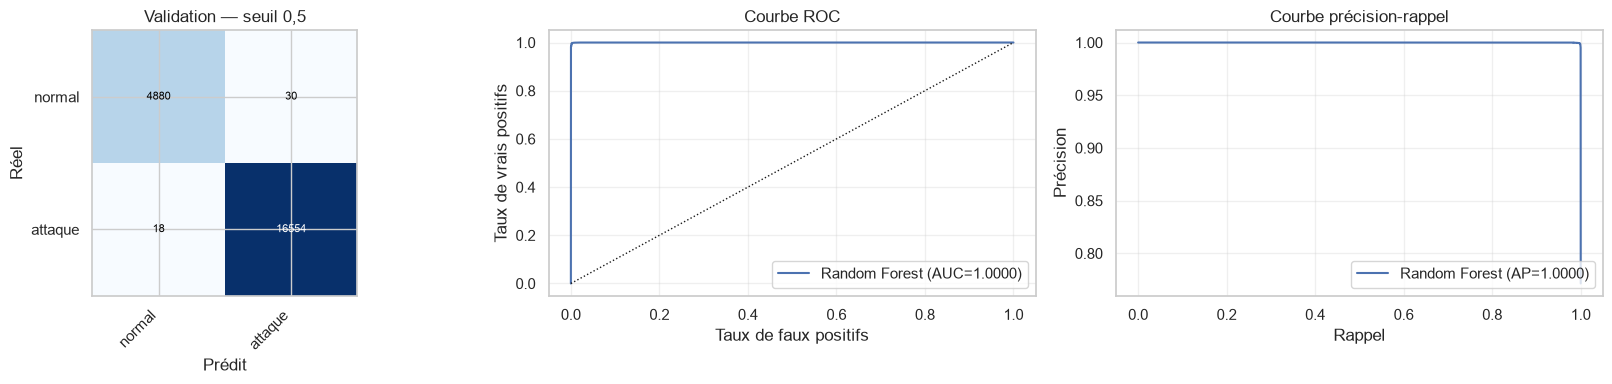

In [7]:
t0 = time.time(); final = make_pipe(best_strategy, **best_params).fit(X_train, ytr); t_fit = time.time() - t0
p_tr, p_va = final.predict_proba(X_train)[:, 1], final.predict_proba(X_valid)[:, 1]
m_tr = U.binary_metrics(ytr, (p_tr >= .5).astype(int), scores=p_tr)
m_va = U.binary_metrics(yva, (p_va >= .5).astype(int), scores=p_va, proba=p_va)
print(f"Temps d'entraînement : {t_fit:.1f}s sur {len(X_train)} lignes")
gap = pd.DataFrame({"train": m_tr, "validation": m_va, "baseline (valid)": base_valid}).T
display(gap[["accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "roc_auc", "pr_auc", "mcc"]].round(4))
print(f"Écart train - validation (F1 macro) : {m_tr['f1_macro'] - m_va['f1_macro']:.4f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
U.plot_confusion(confusion_matrix(yva, (p_va >= .5).astype(int)), ["normal", "attaque"], "Validation — seuil 0,5", ax=axes[0])
U.plot_roc_pr(yva, p_va, "Random Forest", axes=axes[1:]); plt.tight_layout(); U.savefig(fig, "02_valid_eval"); plt.show()

## 7. Seuil de décision et calibration (validation uniquement)

### 7.a Seuil
Le seuil 0,5 n'est pas forcément optimal. `U.best_threshold` choisit, **sur la validation**, le seuil qui maximise le **F1 macro** ; il est appliqué tel quel au test.

Seuil retenu (validation) = 0.6286 — F1 macro validation = 0.9970 (à 0,5 : 0.9968)


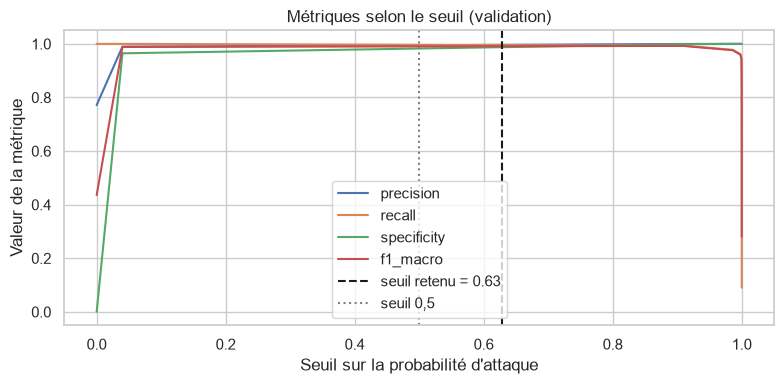

In [8]:
thr, f1m_valid_thr = U.best_threshold(yva, p_va, metric="f1_macro")
print(f"Seuil retenu (validation) = {thr:.4f} — F1 macro validation = {f1m_valid_thr:.4f} (à 0,5 : {m_va['f1_macro']:.4f})")
grid = np.unique(np.quantile(p_va, np.linspace(.01, .99, 80)))
keep = ("precision", "recall", "specificity", "f1_macro")
curve = pd.DataFrame([{"seuil": t, **{k: v for k, v in U.binary_metrics(yva, (p_va >= t).astype(int)).items() if k in keep}} for t in grid]).set_index("seuil")
fig, ax = plt.subplots(figsize=(8, 4)); curve.plot(ax=ax)
ax.axvline(thr, color="k", ls="--", label=f"seuil retenu = {thr:.2f}"); ax.axvline(.5, color="grey", ls=":", label="seuil 0,5")
ax.set(title="Métriques selon le seuil (validation)", xlabel="Seuil sur la probabilité d'attaque", ylabel="Valeur de la métrique"); ax.legend(); plt.tight_layout(); U.savefig(fig, "02_threshold_curve"); plt.show()

### 7.b Calibration des probabilités
Les probabilités d'un Random Forest sont des fréquences de vote : elles ne sont pas forcément calibrées. `U.select_calibrator` compare le score brut, **Platt** et **isotonique** :
ajustement sur une moitié de la validation, Brier mesuré sur l'autre moitié, gagnant réajusté sur toute la validation. **Le test n'intervient pas dans ce choix** (il ne sert qu'à vérifier la fiabilité ensuite).

In [9]:
cal_name, cal_fn, brier_valid = U.select_calibrator(p_va, yva, random_state=RS, is_probability=True)
print("Brier (moitié B de la validation) :"); display(brier_valid.to_frame().T.round(5)); print("Calibrateur retenu :", cal_name)

Brier (moitié B de la validation) :


,platt,isotonic,raw
brier,0.0015,0.0015,0.0015


Calibrateur retenu : raw


## 8. Évaluation finale sur le test (une seule lecture)
Deux points de fonctionnement : seuil par défaut 0,5 et seuil réglé sur la validation. Le tableau officiel du notebook 07 utilise le **seuil réglé** (clé `test`).

,accuracy,balanced_accuracy,precision,recall,specificity,f1,f1_macro,f1_weighted,mcc,fpr,fnr,roc_auc,pr_auc,tn,fp,fn,tp
"Seuil 0,5",0.9986,0.9977,0.9989,0.9993,0.9961,0.9991,0.9979,0.9986,0.9959,0.0039,0.0007,1.0000,1.0000,4847.0000,19.0000,12.0000,16560.0000
Seuil réglé (valid),0.9984,0.9980,0.9992,0.9988,0.9971,0.9990,0.9977,0.9984,0.9955,0.0029,0.0012,1.0000,1.0000,4852.0000,14.0000,20.0000,16552.0000


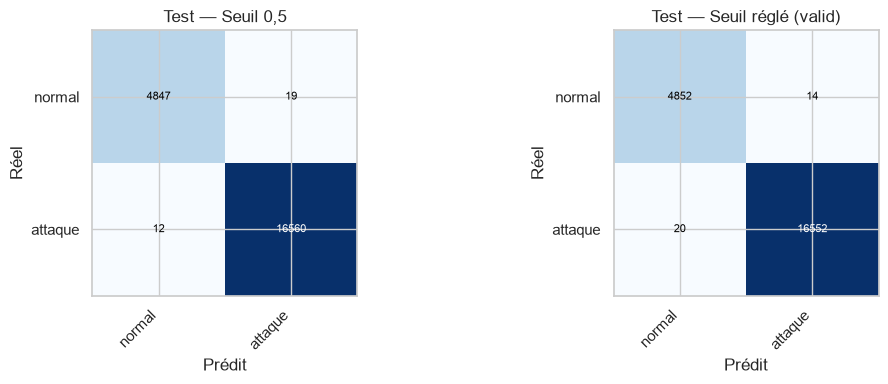

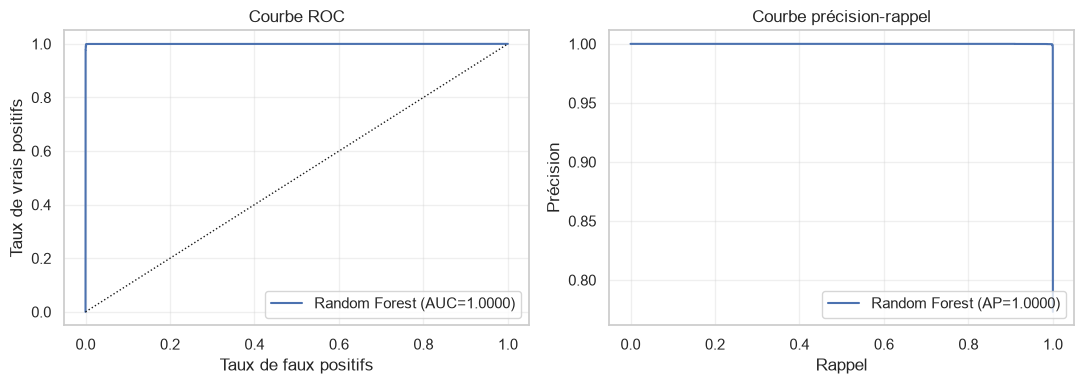

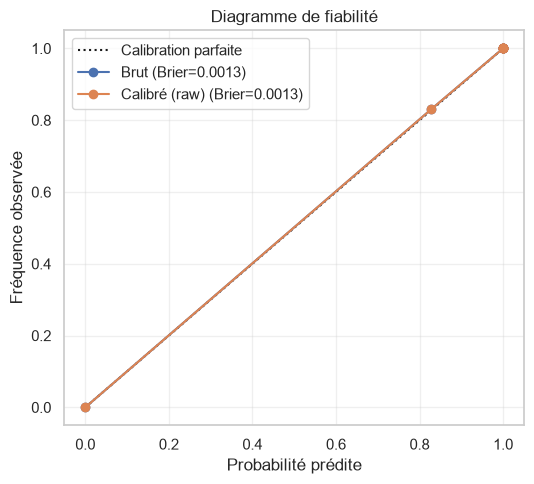

Brier test (information, non utilisé pour choisir) : {'brut': 0.00126, 'raw': 0.00126}


Temps de prédiction : 11.4 ms / 1000 lignes


In [10]:
p_te = final.predict_proba(X_test)[:, 1]; p_te_cal = cal_fn(p_te)
pred = {"Seuil 0,5": (p_te >= .5).astype(int), "Seuil réglé (valid)": (p_te >= thr).astype(int)}
test_tbl = pd.DataFrame({"Seuil 0,5": U.binary_metrics(yte, pred["Seuil 0,5"], scores=p_te, proba=p_te),
                         "Seuil réglé (valid)": U.binary_metrics(yte, pred["Seuil réglé (valid)"], scores=p_te, proba=p_te_cal)}).T
display(test_tbl[["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "f1_macro", "f1_weighted", "mcc", "fpr", "fnr", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp"]].round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (k, v) in zip(axes, pred.items()): U.plot_confusion(confusion_matrix(yte, v), ["normal", "attaque"], f"Test — {k}", ax=ax)
plt.tight_layout(); U.savefig(fig, "02_test_confusions"); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4)); U.plot_roc_pr(yte, p_te, "Random Forest", axes=axes); plt.tight_layout(); U.savefig(fig, "02_test_roc_pr"); plt.show()
fig, ax = plt.subplots(figsize=(5.5, 5)); U.plot_calibration(yte, {"Brut": p_te, f"Calibré ({cal_name})": p_te_cal}, ax=ax)
plt.tight_layout(); U.savefig(fig, "02_calibration"); plt.show()
brier_test = {"brut": float(brier_score_loss(yte, p_te)), cal_name: float(brier_score_loss(yte, p_te_cal))}
print("Brier test (information, non utilisé pour choisir) :", {k: round(v, 5) for k, v in brier_test.items()})
t_pred = U.measure_predict_time(lambda X: final.predict_proba(X), X_valid)
print(f"Temps de prédiction : {t_pred:.1f} ms / 1000 lignes")

## 9. Interprétation et analyse des erreurs

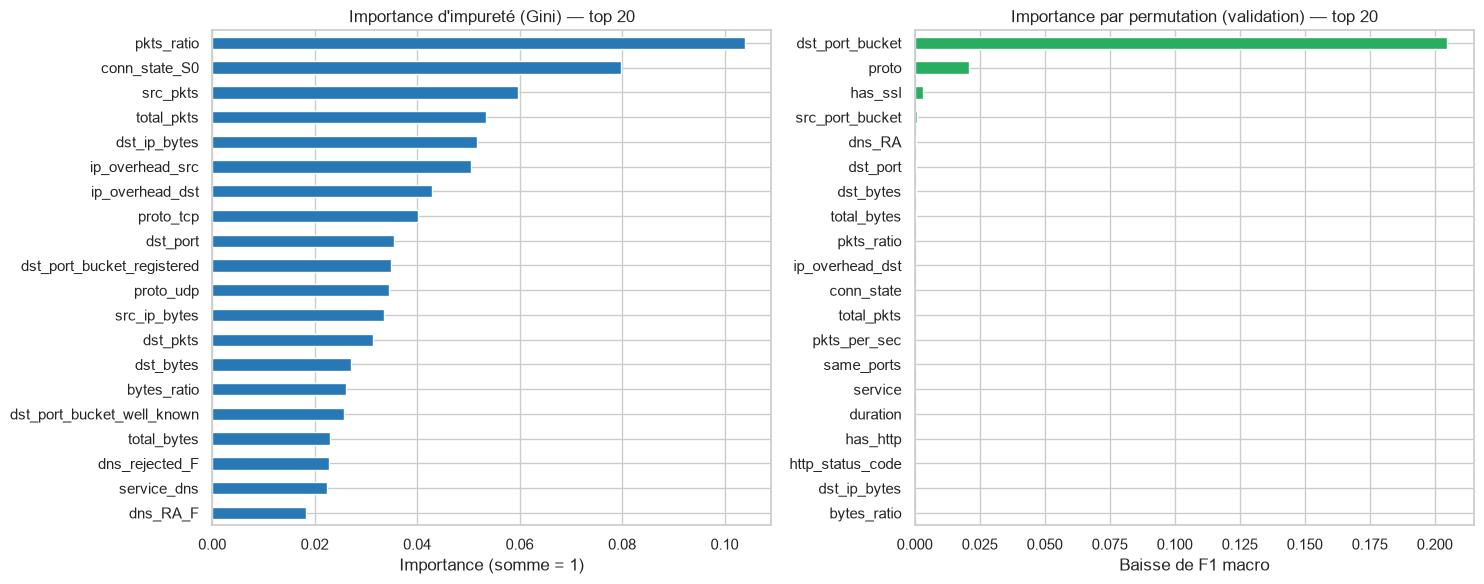

Top 5 Gini : ['pkts_ratio', 'conn_state_S0', 'src_pkts', 'total_pkts', 'dst_ip_bytes']
Top 5 permutation : ['dst_port_bucket', 'proto', 'has_ssl', 'src_port_bucket', 'dns_RA']


In [11]:
names = U.feature_names(final.named_steps["pre"])
imp = pd.Series(final.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
sidx = X_valid.sample(8000, random_state=RS).index
pi = permutation_importance(final, X_valid.loc[sidx], yva[X_valid.index.get_indexer(sidx)], scoring="f1_macro", n_repeats=3, random_state=RS, n_jobs=N_JOBS)
pi_s = pd.Series(pi.importances_mean, index=X_valid.columns).sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(20).iloc[::-1].plot(kind="barh", ax=axes[0], color="#2878b5"); axes[0].set(title="Importance d'impureté (Gini) — top 20", xlabel="Importance (somme = 1)")
pi_s.head(20).iloc[::-1].plot(kind="barh", ax=axes[1], color="#27ae60"); axes[1].set(title="Importance par permutation (validation) — top 20", xlabel="Baisse de F1 macro")
plt.tight_layout(); U.savefig(fig, "02_importances"); plt.show()
print("Top 5 Gini :", list(imp.head(5).index)); print("Top 5 permutation :", list(pi_s.head(5).index))

,n,erreurs,taux_erreur
type,,,
normal,4866,14,0.0029
ransomware,247,1,0.0040
scanning,1187,0,0.0000
backdoor,485,0,0.0000
dos,2882,2,0.0007
mitm,198,10,0.0505
xss,1745,2,0.0011
ddos,2657,2,0.0008
injection,3956,2,0.0005


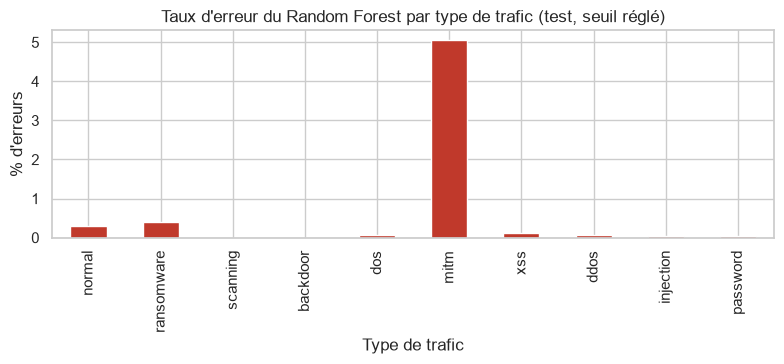

,TP,TN,FP,FN
has_ssl,0.0000,0.0000,0.0000,0.0000
dst_port,80.0000,1391.0000,443.0000,53.0000
dst_bytes,90.0000,0.0000,3571.5000,38.0000
total_bytes,192.0000,116.0000,5342.0000,456.0000
pkts_ratio,0.7140,3.0000,0.9470,0.7050
ip_overhead_dst,112.0000,0.0000,392.0000,14.0000
total_pkts,6.0000,6.0000,19.5000,7.5000
pkts_per_sec,325.1770,488.0440,5.2360,70.2220


In [12]:
err = pd.DataFrame({"type": y_te["type"].to_numpy(), "label": yte, "pred": pred["Seuil réglé (valid)"]}); err["erreur"] = err.label != err.pred
by_type = err.groupby("type").agg(n=("erreur", "size"), erreurs=("erreur", "sum"), taux_erreur=("erreur", "mean")).reindex(TYPE_ORDER)
display(by_type.round(4))
fig, ax = plt.subplots(figsize=(8, 3.8)); by_type["taux_erreur"].mul(100).plot(kind="bar", ax=ax, color="#c0392b")
ax.set(xlabel="Type de trafic", ylabel="% d'erreurs", title="Taux d'erreur du Random Forest par type de trafic (test, seuil réglé)")
plt.tight_layout(); U.savefig(fig, "02_error_by_type"); plt.show()
# caractéristiques des erreurs : médianes des variables numériques les plus importantes (permutation) selon TP / TN / FP / FN
grp = np.select([(err.label == 1) & (err.pred == 1), (err.label == 0) & (err.pred == 0), (err.label == 0) & (err.pred == 1)], ["TP", "TN", "FP"], "FN")
top_num = [c for c in pi_s.index if c in NUM][:8]
med = X_test[top_num].groupby(grp).median().T.round(3)
display(med[[c for c in ["TP", "TN", "FP", "FN"] if c in med.columns]])

## 10. Sauvegarde

In [13]:
joblib.dump(final, U.MODEL_DIR / "rf_anomaly.joblib", compress=3)
U.save_result("02_rf_anomaly", {
    "task": "Détection d'anomalies (label binaire)", "model": "Random Forest", "strategy": best_strategy, "params": best_params,
    "n_train_rows": len(X_train), "fit_time_s": t_fit, "predict_time_ms_per_1k": t_pred,
    "threshold": thr, "threshold_metric": "f1_macro (validation)", "calibrator": cal_name, "calibration_brier_valid_halfB": brier_valid.to_dict(),
    "cv": {"protocole": "StratifiedKFold(3), 50k lignes du train", "selection": "parcimonie (1 écart-type)", "table": bal.to_dict("index")},
    "baseline_valid": base_valid, "train_default_threshold": m_tr, "valid_default_threshold": m_va,
    "valid": U.binary_metrics(yva, (p_va >= thr).astype(int), scores=p_va, proba=cal_fn(p_va)),
    "test": test_tbl.loc["Seuil réglé (valid)"].to_dict(), "test_default_threshold": test_tbl.loc["Seuil 0,5"].to_dict(),
    "brier_test": brier_test, "error_by_type": by_type["taux_erreur"].to_dict(),
    "limitations": [
        "Seuil, calibrateur et hyper-paramètres choisis sur validation / CV d'un sous-échantillon de 50 000 lignes, jamais sur le test.",
        "Données issues d'un banc d'essai scripté (TON_IoT) : la performance ne se transfère pas telle quelle à un autre réseau.",
        "Aucune adresse IP ni port source éphémère dans les variables : le modèle ne mémorise plus l'environnement du banc d'essai.",
        "Random Forest ~ 1,0 sur le train : écart train / validation à surveiller ; modèle supervisé, il ne détecte pas les attaques jamais vues.",
    ]})
print("Modèle et résultats sauvegardés.")

Modèle et résultats sauvegardés.


In [14]:
display(Markdown(f"""### Chiffres clés (générés par le code)
- Stratégie retenue : **{U.STRATEGY_LABELS[best_strategy]}** (argmax brut : {U.STRATEGY_LABELS[argmax_strategy]}) ; hyper-paramètres : `{best_params}`
- F1 macro : train {m_tr['f1_macro']:.4f} / validation (seuil 0,5) {m_va['f1_macro']:.4f} / test (seuil réglé) {test_tbl.loc['Seuil réglé (valid)','f1_macro']:.4f}
- Seuil réglé {thr:.3f} ; calibrateur {cal_name} ; temps d'entraînement {t_fit:.0f}s ; prédiction {t_pred:.0f} ms / 1000 lignes
"""))

### Chiffres clés (générés par le code)
- Stratégie retenue : **Aucun** (argmax brut : SMOTE) ; hyper-paramètres : `{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}`
- F1 macro : train 0.9998 / validation (seuil 0,5) 0.9968 / test (seuil réglé) 0.9977
- Seuil réglé 0.629 ; calibrateur raw ; temps d'entraînement 6s ; prédiction 11 ms / 1000 lignes


## Conclusion (Random Forest — détection d'anomalies)

Chiffres tirés des sorties ci-dessus (cellule « Chiffres clés » et §3 à §9).
- **Équilibrage** : les cinq stratégies sont à 0,0003 de F1 macro les unes des autres (0,9966 à 0,9969), soit l'ordre de grandeur de l'écart-type entre plis. L'`argmax` brut désigne SMOTE, mais la règle de parcimonie retient **aucun rééchantillonnage** : la différence n'est pas significative. SMOTE / SMOTENC améliorent légèrement la spécificité (≈ 0,995 contre 0,993) au prix d'un rappel un peu plus bas ; l'effet est faible ici car le déséquilibre (23 % / 77 %) est modéré.
- **Réglage** : le meilleur tirage (100 arbres, profondeur 20) n'améliore pas la baseline par défaut (F1 macro validation 0,9968 contre 0,9969) : le Random Forest par défaut est déjà à son plateau.
- **Écart train / validation** : F1 macro 0,9998 sur le train contre 0,9968 en validation (écart 0,003). Le RF mémorise le train (score ≈ 1) mais généralise bien aux données non vues ; validation et test sont cohérents (test 0,9977 au seuil réglé).
- **Seuil et calibration** : le seuil réglé sur la validation (≈ 0,63) échange un peu de rappel contre de la spécificité ; sur le test il ne change pas le F1 macro de façon significative (0,9977 contre 0,9979 à 0,5) : l'optimum de validation est dans le bruit. Les probabilités brutes sont déjà bien calibrées (Brier identique pour brut, Platt et isotonique sur la validation) : le calibrateur retenu est le score brut.
- **Erreurs** : très peu d'erreurs ; la classe `mitm` est la plus mal reconnue (≈ 5 % d'erreur, 198 lignes seulement), puis `ransomware` (petit effectif) et le trafic `normal` (faux positifs ≈ 0,3 %).
- **Mise en garde honnête** : après le correctif de fuite les scores restent très élevés (≈ 0,998). Les données TON_IoT sont issues d'un banc d'essai scripté, donc très séparables ; l'importance par permutation est portée par des variables de service (catégories de port, protocole), ce qui suggère que le modèle apprend la signature des services du banc d'essai. Ces performances ne doivent pas être extrapolées à un autre réseau.